# Assignment 5 — ANOVA and Simple Linear Regression
**Group members:** Daniel Munteanu, Josip Brljevic, Luca Mouawad, Zygmunt Tadeusz Kwasniewicz

# Part 1 — Composite strength across curing methods
#### The file *assignment05_composite_strength.csv* contains independent composite specimens cured by four methods. The response is `strength_mpa`; the factor is `curing_method`.

### a) Identify the population, observational unit, response, factor, and factor levels. Explain what additional design information would be needed for a causal claim about curing method.



### b) Report group sample sizes, means, and sample standard deviations. Create side‑by‑side boxplots and describe between‑group differences and within‑group variation.

### c) State the one‑way ANOVA hypotheses. Explain why a collection of unadjusted pairwise *t*‑tests is a poor default.

### d) Fit the classical one‑way model and produce an ANOVA table. Report sums of squares, degrees of freedom, mean squares, *F*, *p* and explain what the *F* ratio compares.

# Part 2 — Diagnostics, post‑hoc comparisons, and magnitude
#### Continue with the composite‑strength study.

### a) Diagnose independence from the study description and inspect within‑group errors using group spreads, residual‑versus‑fitted, and a QQ‑plot of residuals. Explain why the pooled raw response is not the correct normality diagnostic.

### b) Decide whether the classical common‑variance model is credible. Also run Welch's one‑way ANOVA as a sensitivity analysis and explain why it is not paired automatically with ordinary Tukey HSD.



### c) Calculate η² and interpret it as a descriptive fraction of observed squared variation, not causation.



### d) If the classical omnibus test is relevant and significant, perform Tukey HSD. Report simultaneous pairwise intervals and adjusted *p*‑values and identify which curing methods are distinguishable. Do not treat a non‑significant pair as proof of equal means.

### e) Write a recommendation in MPa that distinguishes the global question, specific pairwise differences, practical importance, and design limitations.

# Part 3 — Pump flow and energy use
#### The file *assignment05_pump_energy.csv* contains independent benchmark runs over an observed flow‑rate range. Let energy use be *Y* and flow rate be *x*, with the statistical model *Y* = β₀ + β₁ x + ε

### a) Identify the population, observational unit, response, predictor, and observed predictor range. Create a scatterplot and discuss whether a linear conditional‑mean model is plausible before fitting it.

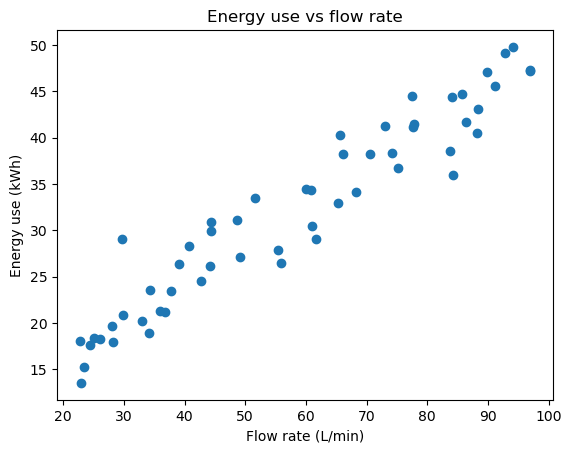


Population: all benchmark runs of this pump under the same test conditions, at flow rates between 22.7 and 97.0 L/min \
Observational unit: one benchmark run \
Response $Y$: energy use (kWh) \
Predictor $x$: flow rate (L/min) \
Observed range of $x$: 22.7 to 97.0 L/min, $n = 55$ runs \
Using the line outside this range would be extrapolation.

The points rise together in a roughly straight band. There is no clear curve and the spread around the band looks about the same at low and high flow, so a straight line for the mean energy use looks plausible. \
One run at about 30 L/min lies higher than its neighbours, and it should be checked with the residual plots in Part 4.


In [5]:
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import pandas as pd

pump = pd.read_csv("assignment05_pump_energy.csv")
x = pump["flow_l_min"]
y = pump["energy_kwh"]
n = len(pump)

plt.scatter(x, y)
plt.xlabel("Flow rate (L/min)")
plt.ylabel("Energy use (kWh)")
plt.title("Energy use vs flow rate")
plt.show()

display(Markdown(f"""
Population: all benchmark runs of this pump under the same test conditions, at flow rates between {x.min()} and {x.max()} L/min \\
Observational unit: one benchmark run \\
Response $Y$: energy use (kWh) \\
Predictor $x$: flow rate (L/min) \\
Observed range of $x$: {x.min()} to {x.max()} L/min, $n = {n}$ runs \\
Using the line outside this range would be extrapolation.

The points rise together in a roughly straight band. There is no clear curve and the spread around the band looks about the same at low and high flow, so a straight line for the mean energy use looks plausible. \\
One run at about 30 L/min lies higher than its neighbours, and it should be checked with the residual plots in Part 4.
"""))

### b) Fit an intercept model with statsmodels. Report and interpret β̂₀, β̂₁, residual standard deviation, Pearson correlation *r*, and R². Include units and discuss whether the intercept has a useful engineering interpretation.


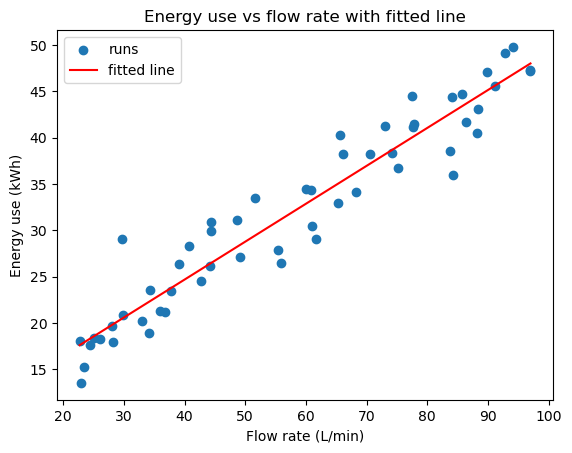


Fitted line: $\hat y = 8.318 + 0.4092\,x$ \
$\hat\beta_0 = 8.318$ kWh \
$\hat\beta_1 = 0.4092$ kWh per L/min \
Residual standard deviation $s = 2.938$ kWh \
Pearson correlation $r = 0.958$ \
$R^2 = 0.918$

Slope: each extra L/min of flow is associated with 0.409 kWh higher mean energy use, so 10 L/min more gives about 4.09 kWh more on average. \
Residual standard deviation: a single run typically lies about 2.94 kWh above or below the line. \
$r$: there is a strong positive linear association between flow rate and energy use. \
$R^2$: about 91.8% of the variation in energy use is accounted for by the line.

Intercept: 8.32 kWh would be the mean energy use at 0 L/min. Zero flow is far outside the observed range (22.7 to 97.0 L/min), so this is extrapolation. The intercept only anchors the line and should not be read as the energy use of an idle pump.


In [6]:
import statsmodels.formula.api as smf
import numpy as np

model = smf.ols("energy_kwh ~ flow_l_min", data=pump).fit()

b0 = model.params["Intercept"]
b1 = model.params["flow_l_min"]
s = np.sqrt(model.scale)
r = x.corr(y)
r2 = model.rsquared

plt.scatter(x, y, label="runs")
plt.plot(x, b0 + b1 * x, color="red", label="fitted line")
plt.xlabel("Flow rate (L/min)")
plt.ylabel("Energy use (kWh)")
plt.title("Energy use vs flow rate with fitted line")
plt.legend()
plt.show()

display(Markdown(rf"""
Fitted line: $\hat y = {b0:.3f} + {b1:.4f}\,x$ \
$\hat\beta_0 = {b0:.3f}$ kWh \
$\hat\beta_1 = {b1:.4f}$ kWh per L/min \
Residual standard deviation $s = {s:.3f}$ kWh \
Pearson correlation $r = {r:.3f}$ \
$R^2 = {r2:.3f}$

Slope: each extra L/min of flow is associated with {b1:.3f} kWh higher mean energy use, so 10 L/min more gives about {10*b1:.2f} kWh more on average. \
Residual standard deviation: a single run typically lies about {s:.2f} kWh above or below the line. \
$r$: there is a strong positive linear association between flow rate and energy use. \
$R^2$: about {r2*100:.1f}% of the variation in energy use is accounted for by the line.

Intercept: {b0:.2f} kWh would be the mean energy use at 0 L/min. Zero flow is far outside the observed range ({x.min()} to {x.max()} L/min), so this is extrapolation. The intercept only anchors the line and should not be read as the energy use of an idle pump.
"""))




### c) Verify that R² = r² for this simple intercept model. Explain what correlation and R² measure and what they do not establish.





In [7]:
display(Markdown(rf"""
$r = {r:.4f}$ \
$r^2 = {r**2:.4f}$ \
$R^2 = {r2:.4f}$ \
$R^2 = r^2$: {np.isclose(r2, r**2)}

The correlation $r$ measures the direction and how closely the points follow a straight line. It lies between $-1$ and $1$ and has no units. Here $r = {r:.3f}$ is a strong positive linear association. \
$R^2$ measures the share of the variation in energy use that the line accounts for, here about {r2*100:.1f}%.

Neither tells how much energy changes with flow. That is the slope, {b1:.3f} kWh per L/min. \
A high $r$ or $R^2$ does not show that flow causes the energy use. The file does not show that the flow settings were run in random order, and something else could change together with flow. \
A high $R^2$ also does not show that a straight line is the right model. That has to be checked with the residual plots. \
An $r$ close to 0 would not mean no relationship, since a curved relationship can have $r$ near 0.
"""))


$r = 0.9581$ \
$r^2 = 0.9179$ \
$R^2 = 0.9179$ \
$R^2 = r^2$: True

The correlation $r$ measures the direction and how closely the points follow a straight line. It lies between $-1$ and $1$ and has no units. Here $r = 0.958$ is a strong positive linear association. \
$R^2$ measures the share of the variation in energy use that the line accounts for, here about 91.8%.

Neither tells how much energy changes with flow. That is the slope, 0.409 kWh per L/min. \
A high $r$ or $R^2$ does not show that flow causes the energy use. The file does not show that the flow settings were run in random order, and something else could change together with flow. \
A high $R^2$ also does not show that a straight line is the right model. That has to be checked with the residual plots. \
An $r$ close to 0 would not mean no relationship, since a curved relationship can have $r$ near 0.


### d) Test H₀: β₁ = 0 against a two‑sided alternative. Report the slope estimate, standard error, 95 % interval, *t*‑statistic, degrees of freedom, and *p*‑value. State the conclusion as an association, not automatically as causation.

In [8]:
se_b1 = model.bse["flow_l_min"]
t_obs = model.tvalues["flow_l_min"]
p_b1 = model.pvalues["flow_l_min"]
df_res = int(model.df_resid)
ci_low, ci_high = model.conf_int(alpha=0.05).loc["flow_l_min"]

display(Markdown(rf"""
$H_0$: $\beta_1 = 0$ (no linear association between flow rate and mean energy use) \
$H_1$: $\beta_1 \neq 0$ \
$\alpha = 0.05$

Slope estimate $\hat\beta_1 = {b1:.4f}$ kWh per L/min \
Standard error $SE(\hat\beta_1) = {se_b1:.4f}$ kWh per L/min \
95% confidence interval: [{ci_low:.3f}, {ci_high:.3f}] kWh per L/min \
$t = \hat\beta_1 / SE(\hat\beta_1) = {t_obs:.2f}$ \
$df = n - 2 = {df_res}$ \
two-sided $p$-value $= {p_b1:.2e}$

Since $p < 0.05$, $H_0$ is rejected. The 95% interval does not contain 0, which agrees with the test. \
Mean energy use increases with flow rate, by about {b1:.3f} kWh per L/min (between {ci_low:.3f} and {ci_high:.3f}). \
This is an association. It does not by itself show that flow rate causes the energy use, because the data do not show that the flow settings were assigned in random order and other conditions could change together with flow.
"""))


$H_0$: $\beta_1 = 0$ (no linear association between flow rate and mean energy use) \
$H_1$: $\beta_1 \neq 0$ \
$\alpha = 0.05$

Slope estimate $\hat\beta_1 = 0.4092$ kWh per L/min \
Standard error $SE(\hat\beta_1) = 0.0168$ kWh per L/min \
95% confidence interval: [0.375, 0.443] kWh per L/min \
$t = \hat\beta_1 / SE(\hat\beta_1) = 24.35$ \
$df = n - 2 = 53$ \
two-sided $p$-value $= 1.90e-30$

Since $p < 0.05$, $H_0$ is rejected. The 95% interval does not contain 0, which agrees with the test. \
Mean energy use increases with flow rate, by about 0.409 kWh per L/min (between 0.375 and 0.443). \
This is an association. It does not by itself show that flow rate causes the energy use, because the data do not show that the flow settings were assigned in random order and other conditions could change together with flow.


# Part 4 — Regression diagnostics and prediction
#### Continue with the pump study.

### a) Create residual‑versus‑fitted, residual‑versus‑run‑order, and normal QQ‑plots. Discuss linearity, constant spread, unusual observations, normal‑error approximation, and what the plots cannot establish about independence or sampling.

### b) Calculate leverage and Cook’s distance. Identify the most influential run, investigate it rather than deleting it automatically, and explain what operational information you would seek.







### c) At *x*₀ = 70 L min⁻¹, report the fitted mean energy, a 95 % confidence interval for the mean energy, and a 95 % prediction interval for one new run. Explain why the prediction interval is wider.





### d) Explain why using this fitted line at 10 or 120 L min⁻¹ would be extrapolation. State what evidence would be needed before extending the relationship outside the observed range.





### e) Give a practical conclusion that includes slope in kWh per L min, uncertainty, residual variation, R², prediction uncertainty, and study‑design limitations.


# Part 5 — AI‑use and conclusion
#### AI‑use
State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. A short paragraph or table is sufficient.



#### Overall conclusion
Write approximately 150–250 words comparing ANOVA and regression as methods for a quantitative response. Explain how the type of predictor determines the question, how residuals are used in both analyses, and why statistical modelling does not by itself prove causation.


